In [ ]:
---
execute:
  eval: false
  echo: true
  warning: false
format:
  html:
    code-fold: false
---

Importing the packages.

In [1]:
#| echo: true
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

Generating two random distributions.

In [3]:
#| echo: true
n_samples = 2000
x0 = torch.randn(n_samples, 2) + torch.tensor([-3.0, -3.0])
x1 = torch.randn(n_samples, 2) * 0.5 + torch.tensor([3.0, 3.0])

Creating a FM model.

In [4]:
#| echo: true
class FM(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 128),
            nn.SiLU(),
            nn.Linear(128, 128),
            nn.SiLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x, t):
        inp = torch.cat([x, t], dim=-1)
        return self.net(inp)

Training the FM model.

In [ ]:
#| echo: true
model = FM()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 3000
batch_size = 256

for epoch in range(epochs):
    idx = torch.randint(0, n_samples, (batch_size,))
    batch_x0 = x0[idx]
    batch_x1 = x1[idx]

    t = torch.rand(batch_size, 1)
    xt = t * batch_x1 + (1 - t) * batch_x0
    target_v = batch_x1 - batch_x0

    pred_v = model(xt, t)
    loss = torch.nn.functional.mse_loss(pred_v, target_v)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

Generating samples from the prior.

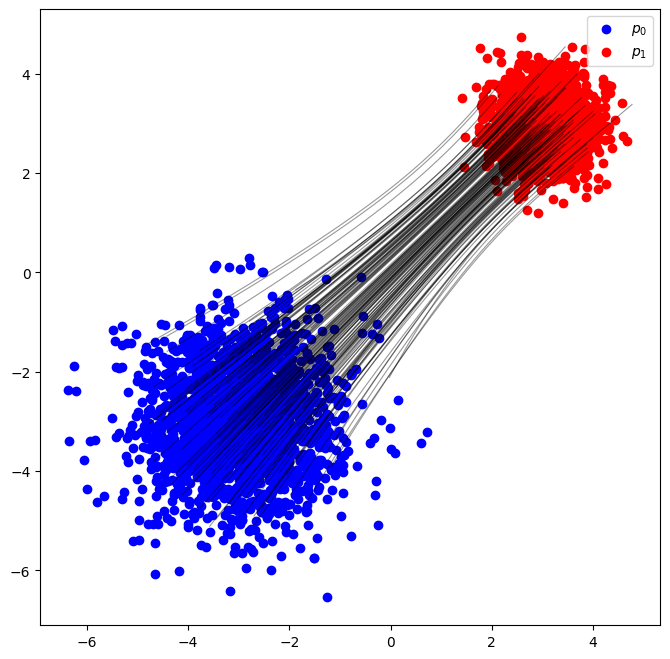

In [7]:
#| echo: true
steps = 50
dt = 1.0 / steps

test_x = torch.randn(150, 2) + torch.tensor([-3.0, -3.0])
trajectories = [test_x.clone()]

with torch.no_grad():
    for i in range(steps):
        t = torch.ones(150, 1) * (i * dt)
        v = model(test_x, t)
        test_x = test_x + v * dt
        trajectories.append(test_x.clone())

trajectories = torch.stack(trajectories)

plt.figure(figsize=(8, 8))
plt.scatter(x0[:, 0].numpy(), x0[:, 1].numpy(), c='blue', label=r"$p_0$")
plt.scatter(x1[:, 0].numpy(), x1[:, 1].numpy(), c='red', label=r"$p_1$")

for i in range(150):
    plt.plot(trajectories[:, i, 0].numpy(), trajectories[:, i, 1].numpy(), color='black', alpha=0.4, linewidth=0.8)

plt.legend()
plt.show()